<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">

# فاز اول: تشخیص فرمان‌های گفتاری برای گویندگان جدید
**فاز اول پروژهٔ تحلیل داده**

در این نوت‌بوک داده را می‌شناسیم، کیفیت را اندازه می‌گیریم و تقسیم بدون اشتراک گوینده می‌سازیم. هنوز مدل پیش‌بینی آموزش نمی‌دهیم. هدف این است که هر تصمیم قابل توضیح و بازاجرا باشد.

**دامنه:** Mini Speech Commands با هشت فرمان. دادهٔ خام دانلود می‌شود ولی تغییر نمی‌کند. نمودارهای اکتشافی فقط روی آموزش و پس از کنارگذاشتن نسخهٔ اضافی موج‌های یکسان ساخته می‌شوند. خروجی‌های ذخیره‌شدهٔ این نوت‌بوک مربوط به اجرای واقعی‌اند.

</div>

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">

## ۱. سؤال و واحد مشاهده
سؤال اصلی: روش‌های تشخیص فرمان تا چه اندازه به گویندگان غایب از آموزش تعمیم می‌یابند؟

دو سؤال دیگر: کیفیت صوت در فرمان‌ها و گویندگان چه تفاوتی دارد؟ در فازهای بعد نویز چه اثری بر عملکرد می‌گذارد؟

هر ردیف جدول موجودی یک فایل صوتی است؛ هر گوینده ممکن است چند فایل و چند فرمان داشته باشد. به همین دلیل تقسیم تصادفی ردیف‌ها می‌تواند گویندهٔ مشابه را به آموزش و آزمون وارد کند.

</div>

In [1]:
from pathlib import Path
import sys, json, zipfile, io
import pandas as pd
from IPython.display import display, Image, Audio
ROOT = Path.cwd()
if not (ROOT / "configs/phase1.json").exists():
    ROOT = ROOT.parent
assert (ROOT / "configs/phase1.json").exists(), "نوت‌بوک را از ریشه یا پوشه notebooks اجرا کنید"
sys.path.insert(0, str(ROOT / "src"))
from persian_display import setup_notebook, display_table, fa, T
from phase1 import audit, decode
FONT = setup_notebook(ROOT)
cfg = json.loads((ROOT / "configs/phase1.json").read_text(encoding="utf-8"))
display_table(pd.Series(cfg, name="پیکربندی"))

فونت نمودار: Tahoma


,پیکربندی
dataset_url,https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip
archive_sha256,49650f2341b26d886b46b3f4fb8fed59e30300b17550f1ee4a768b3106cf93a0
classes,"[down, go, left, no, right, stop, up, yes]"
split_salt,mehrshad-phase1-v1
train_fraction,0.7
validation_fraction,0.15
low_energy_dbfs,-40
frame_low_energy_dbfs,-45
frame_ms,20
clipping_fraction_threshold,0.001


<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">

## ۲. اجرای ممیزی و تولید شکل‌ها
کد زیر آرشیو را در صورت نیاز از منبع رسمی می‌گیرد، هش آن را بررسی می‌کند و تمام ۸۰۰۰ فایل را می‌خواند. شاخص‌های هر فایل مستقل از سایر فایل‌ها محاسبه می‌شوند. آستانه‌ها در پیکربندی ثبت شده‌اند و از دادهٔ آزمون تنظیم نشده‌اند.

برای دیدن جزئیات، فایل `src/phase1.py` را بخوانید: `decode` خواندن صوت، `measure` شاخص‌ها، `split_for` تقسیم و `make_figures` رسم را انجام می‌دهند.

</div>

In [2]:
inventory, summary = audit(ROOT)

{
  "dataset": "mini_speech_commands",
  "archive_sha256": "49650f2341b26d886b46b3f4fb8fed59e30300b17550f1ee4a768b3106cf93a0",
  "analysis_files": 7973,
  "analysis_splits": {
    "test": 1359,
    "train": 5382,
    "validation": 1232
  },
  "total_files": 8000,
  "valid_files": 8000,
  "read_errors": 0,
  "speakers": 1750,
  "classes": {
    "down": 1000,
    "go": 1000,
    "left": 1000,
    "no": 1000,
    "right": 1000,
    "stop": 1000,
    "up": 1000,
    "yes": 1000
  },
  "sample_rates": {
    "16000": 8000
  },
  "channels": {
    "1": 8000
  },
  "duration_min": 0.4266875,
  "duration_max": 1.0,
  "shorter_than_1s": 822,
  "all_zero": 0,
  "pcm_duplicate_extra": 27,
  "pcm_duplicate_members": 54,
  "duplicate_label_conflicts": 0,
  "low_energy": 691,
  "clipping_flag": 152,
  "very_short": 0,
  "splits": {
    "test": {
      "files": 1359,
      "speakers": 291
    },
    "train": {
      "files": 5409,
      "speakers": 1193
    },
    "validation": {
      "files": 1232,


<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">

## ۳. نگاه اول به داده و معنای ستون‌ها
`duration_s` طول، `rms_dbfs` انرژی نسبی، `peak` قلهٔ دامنه و `speaker_id` شناسهٔ گروه گوینده است. `use_for_analysis` تعیین می‌کند کدام نسخهٔ موج یکتا وارد تحلیل شود. تعریف تمام ستون‌ها در DATA_DICTIONARY.md آمده است.

</div>

In [3]:
display_table(inventory[["path", "label", "speaker_id", "duration_s", "rms_dbfs", "split", "use_for_analysis"]].head())
display_table(inventory.dtypes.to_frame("نوع ستون"))
display_table(inventory.isna().sum().to_frame("تعداد مقدار گمشده"))

,path,label,speaker_id,duration_s,rms_dbfs,split,use_for_analysis
0,mini_speech_commands/down/004ae714_nohash_0.wav,down,004ae714,1.0,-27.996362,validation,True
1,mini_speech_commands/down/00b01445_nohash_1.wav,down,00b01445,1.0,-23.293237,test,True
2,mini_speech_commands/down/00f0204f_nohash_0.wav,down,00f0204f,1.0,-32.623091,train,True
3,mini_speech_commands/down/0132a06d_nohash_1.wav,down,0132a06d,1.0,-29.366965,train,True
4,mini_speech_commands/down/0132a06d_nohash_4.wav,down,0132a06d,1.0,-21.144921,train,True


,نوع ستون
path,object
label,object
speaker_id,object
file_bytes,int64
file_sha256,object
sample_rate,int64
channels,int64
sample_width_bytes,int64
n_samples,int64
duration_s,float64


,تعداد مقدار گمشده
path,0
label,0
speaker_id,0
file_bytes,0
file_sha256,0
sample_rate,0
channels,0
sample_width_bytes,0
n_samples,0
duration_s,0


,label,test,train,validation
0,down,175,672,153
1,go,175,679,146
2,left,175,664,161
3,no,173,678,149
4,right,163,689,148
5,stop,160,676,164
6,up,156,681,163
7,yes,182,670,148


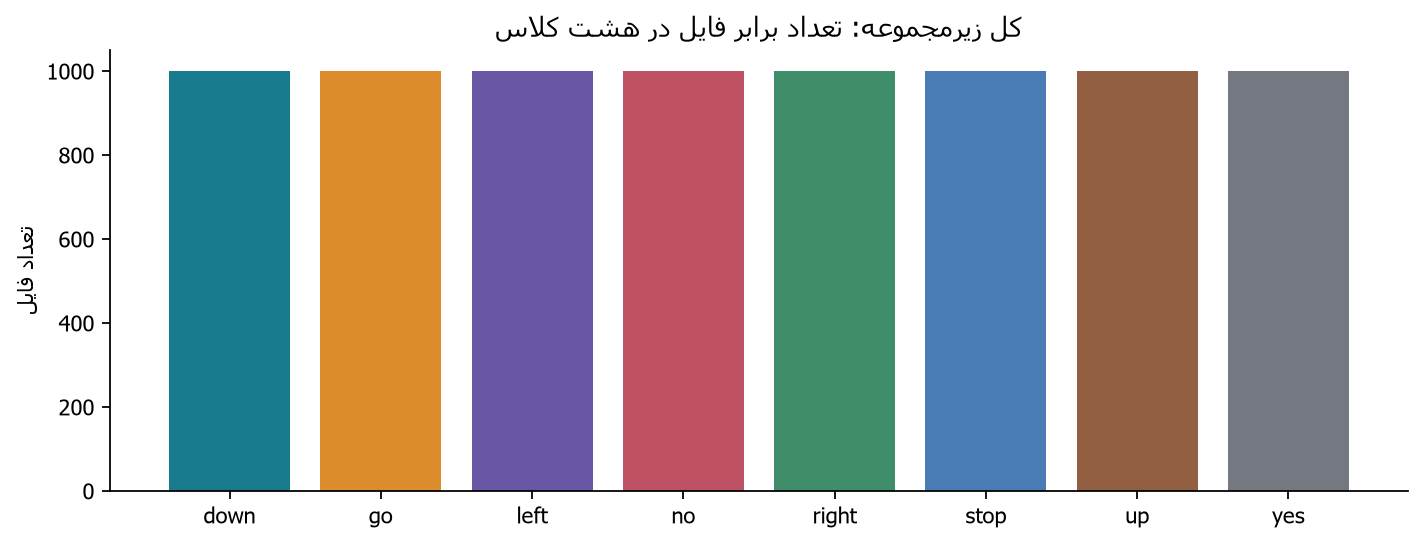

In [4]:
display_table(pd.read_csv(ROOT / "tables/class_split_counts.csv"))
display(Image(filename=str(ROOT / "figures/01_class_balance.png")))

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">

**تفسیر:** دادهٔ خام از نظر تعداد فرمان متوازن است، اما توازن تعداد فایل به معنی توازن گوینده، کیفیت یا توزیع واقعی کاربرد نیست. فرادادهٔ جمعیت‌شناختی اساساً در جدول موجود نیست؛ نبود مقدار خالی در ستون‌های استخراج‌شده به معنی کامل‌بودن اطلاعات جهان واقعی نیست.

</div>

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">

## ۴. کیفیت، تکرار و تصمیم اولیه
تکرار را با PCM رمزگشایی‌شده و نرخ نمونه‌برداری می‌سنجیم، بنابراین اختلاف احتمالی سربرگ WAV مانع تشخیص موج یکسان نیست. یک نسخه نگه داشته می‌شود و اصل داده تغییر نمی‌کند.

کم‌انرژی، اشباع و کوتاهی فقط پرچم‌اند. برای مثال یک فرمان آرام می‌تواند کاملاً معتبر باشد. از حذف خودکار تمام نقاط پرت خودداری می‌کنیم.

</div>

In [5]:
quality = {
    "فایل غیرقابل خواندن": summary["read_errors"],
    "نسخه اضافی موج یکسان": summary["pcm_duplicate_extra"],
    "فایل تمام صفر": summary["all_zero"],
    "پرچم کم‌انرژی در کل داده": summary["low_energy"],
    "پرچم اشباع در کل داده": summary["clipping_flag"],
    "کوتاه‌تر از یک ثانیه": summary["shorter_than_1s"],
}
display_table(pd.Series(quality, name="تعداد"))
display_table(inventory[inventory.exact_duplicate][["path", "label", "speaker_id", "pcm_sha256", "use_for_analysis"]].head(8))

,تعداد
فایل غیرقابل خواندن,0
نسخه اضافی موج یکسان,27
فایل تمام صفر,0
پرچم کم‌انرژی در کل داده,691
پرچم اشباع در کل داده,152
کوتاه‌تر از یک ثانیه,822


,path,label,speaker_id,pcm_sha256,use_for_analysis
738,mini_speech_commands/down/c120e80e_nohash_1.wav,down,c120e80e,e7d7120238a88fdb6b2405aa9e916293dc7909185b0b2367fc7fa8fcc1d8f020,True
739,mini_speech_commands/down/c120e80e_nohash_2.wav,down,c120e80e,cb35832635a765109b2b33cd1f563763b77bd9e3c92d446ac8ce2fcd803f5577,True
741,mini_speech_commands/down/c120e80e_nohash_4.wav,down,c120e80e,e7d7120238a88fdb6b2405aa9e916293dc7909185b0b2367fc7fa8fcc1d8f020,False
742,mini_speech_commands/down/c120e80e_nohash_5.wav,down,c120e80e,cb35832635a765109b2b33cd1f563763b77bd9e3c92d446ac8ce2fcd803f5577,False
1145,mini_speech_commands/go/28ce0c58_nohash_2.wav,go,28ce0c58,d61992992351d1341edb9567a19320a05686455283811ca4207340d12e42b169,True
1146,mini_speech_commands/go/28ce0c58_nohash_3.wav,go,28ce0c58,d61992992351d1341edb9567a19320a05686455283811ca4207340d12e42b169,False
1733,mini_speech_commands/go/c120e80e_nohash_3.wav,go,c120e80e,29c57de95fee60d5d34a1924e6faaefe27e425f890344e1fa80511f9058ba2aa,True
1736,mini_speech_commands/go/c120e80e_nohash_6.wav,go,c120e80e,29c57de95fee60d5d34a1924e6faaefe27e425f890344e1fa80511f9058ba2aa,False


<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">

## ۵. تقسیم مستقل از گوینده
salt ثابت به همراه شناسهٔ گروه هش می‌شود. نسبت هدف ۷۰/۱۵/۱۵ احتمالی است؛ تعداد فایل واقعی به مشارکت گویندگان وابسته است. آمار بخش آزمون صرفاً برای ممیزی تقسیم آمده و هیچ معیار مدل محاسبه نمی‌شود.

دقت شود که این تقسیم رسمی TensorFlow نیست؛ طراحی اختصاصی پروژه است. فایل manifest مرجع تمام فازهای بعد خواهد بود.

</div>

,split,files,speakers
0,test,1359,291
1,train,5382,1193
2,validation,1232,266


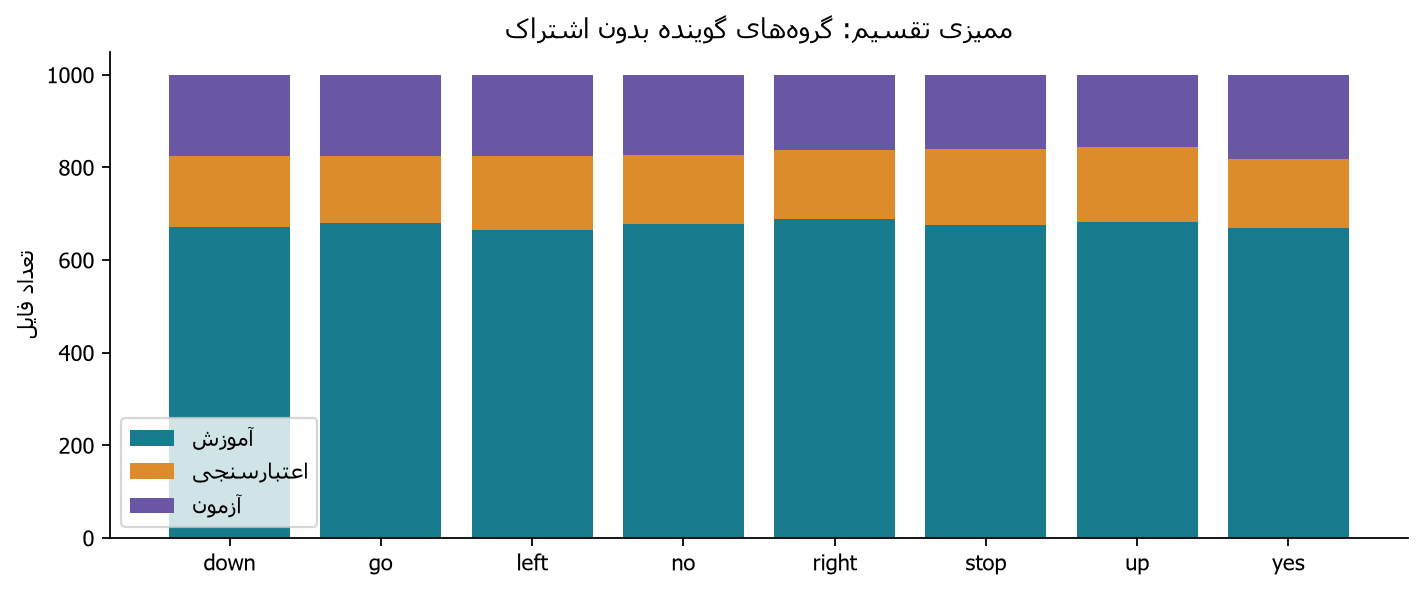

In [6]:
manifest = pd.read_csv(ROOT / "splits/manifest.csv")
assert manifest.groupby("speaker_id").split.nunique().max() == 1
assert manifest.groupby("pcm_sha256").split.nunique().max() == 1
assert not manifest[manifest.use_for_analysis].pcm_sha256.duplicated().any()
display_table(pd.read_csv(ROOT / "tables/analysis_split_summary.csv"))
display(Image(filename=str(ROOT / "figures/10_splits.png")))

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">

## ۶. تحلیل تک‌متغیره و تفاوت گروه‌ها
تنها فایل‌های یکتای آموزش را انتخاب می‌کنیم. طول، انرژی و پراکندگی هر فرمان را بررسی می‌کنیم. کوتاه‌بودن فایل لزوماً نقص نیست. در فاز دوم می‌توان طول را با padding استاندارد کرد؛ اکنون دادهٔ خام حفظ می‌شود.

</div>

,duration_s,rms_dbfs,peak,clipping_fraction,low_energy_frame_fraction
count,5382.000000,5382.000000,5382.000000,5382.000000,5382.000000
mean,0.985736,-28.029444,0.459418,0.000159,0.512683
std,0.056428,9.202437,0.299047,0.002217,0.255855
min,0.426687,-90.019730,0.000153,0.000000,0.000000
25%,1.000000,-32.607186,0.203644,0.000000,0.388642
50%,1.000000,-26.751157,0.396988,0.000000,0.580000
75%,1.000000,-21.797193,0.724319,0.000000,0.680000
max,1.000000,-5.472132,1.000000,0.113625,1.000000


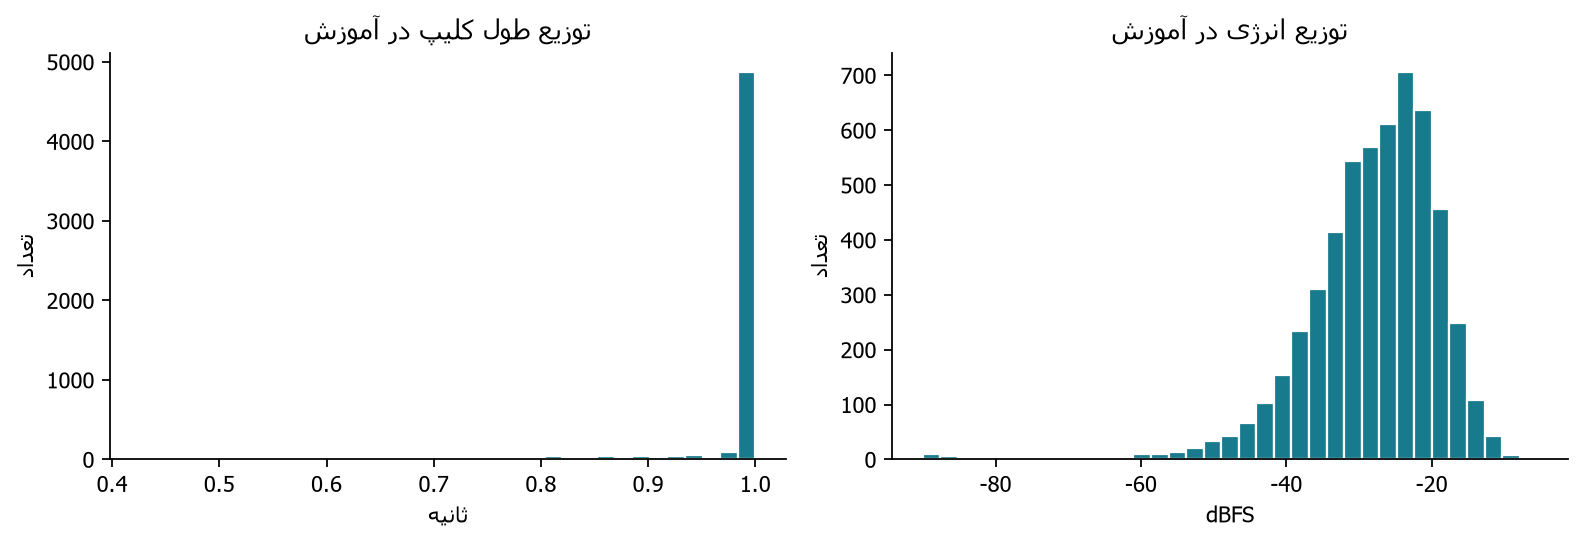

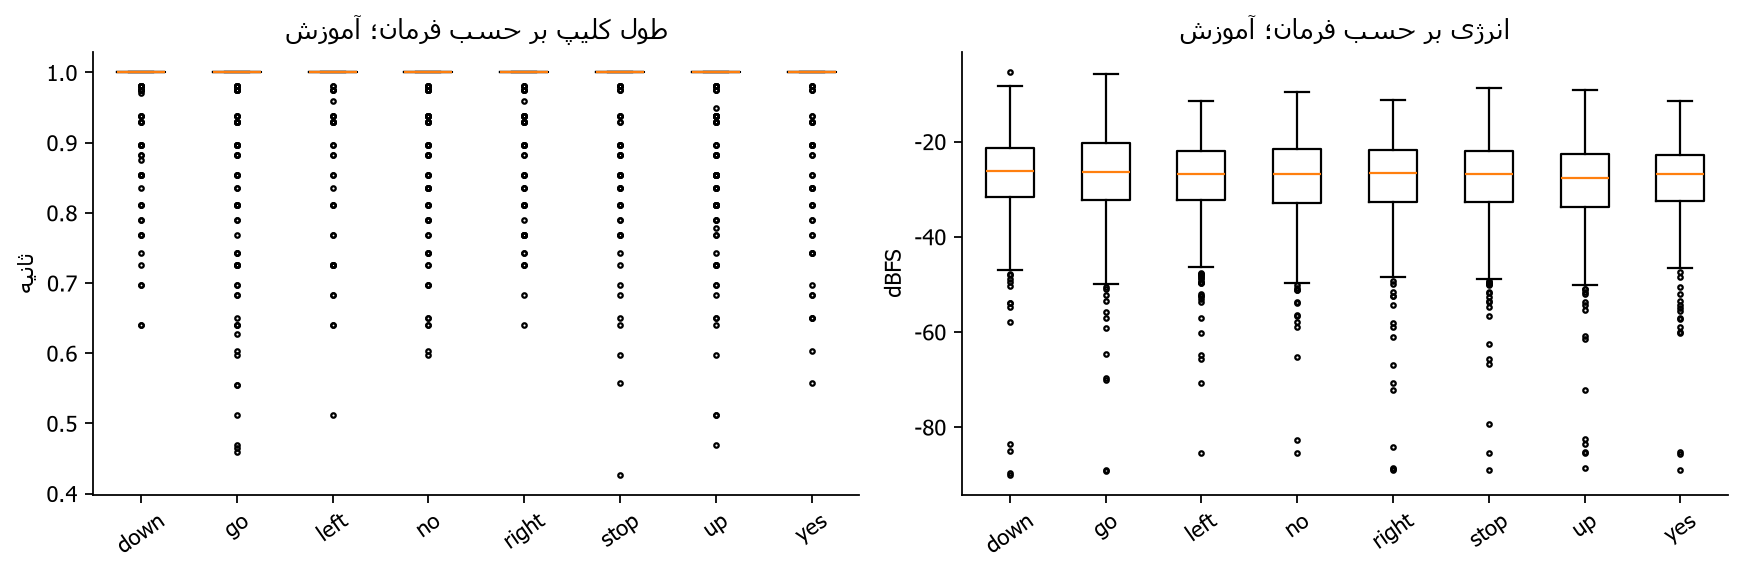

In [7]:
train = inventory[(inventory.split == "train") & inventory.use_for_analysis].copy()
display_table(train[["duration_s", "rms_dbfs", "peak", "clipping_fraction", "low_energy_frame_fraction"]].describe())
for filename in ["02_distributions.png", "03_class_quality.png"]:
    display(Image(filename=str(ROOT / "figures" / filename)))

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">

## ۷. رابطهٔ چند متغیر و حساسیت
همبستگی انرژی و قله بزرگ است چون هر دو به دامنه وابسته‌اند؛ این رابطه اثبات علّی نیست. نسبت قاب کم‌انرژی نیز از همان مفهوم انرژی ساخته می‌شود. در آستانهٔ منفی ۴۰ دسی‌بل، ۴۳۴ فایل آموزشی علامت می‌خورند؛ تغییر آستانه تعداد را زیاد تغییر می‌دهد، پس پرچم را تشخیص قطعی خرابی نمی‌دانیم.

</div>

,duration_s,rms_dbfs,peak,dc_offset,clipping_fraction,low_energy_frame_fraction
duration_s,1.000000,0.046822,0.069786,-0.021883,-0.006480,0.085161
rms_dbfs,0.046822,1.000000,0.936886,0.031548,0.319667,-0.520151
peak,0.069786,0.936886,1.000000,0.018279,0.352467,-0.405862
dc_offset,-0.021883,0.031548,0.018279,1.000000,-0.016115,-0.024407
clipping_fraction,-0.006480,0.319667,0.352467,-0.016115,1.000000,-0.211938
low_energy_frame_fraction,0.085161,-0.520151,-0.405862,-0.024407,-0.211938,1.000000


,threshold_dbfs,train_clips_below
0,-50,105
1,-45,208
2,-40,434
3,-35,966


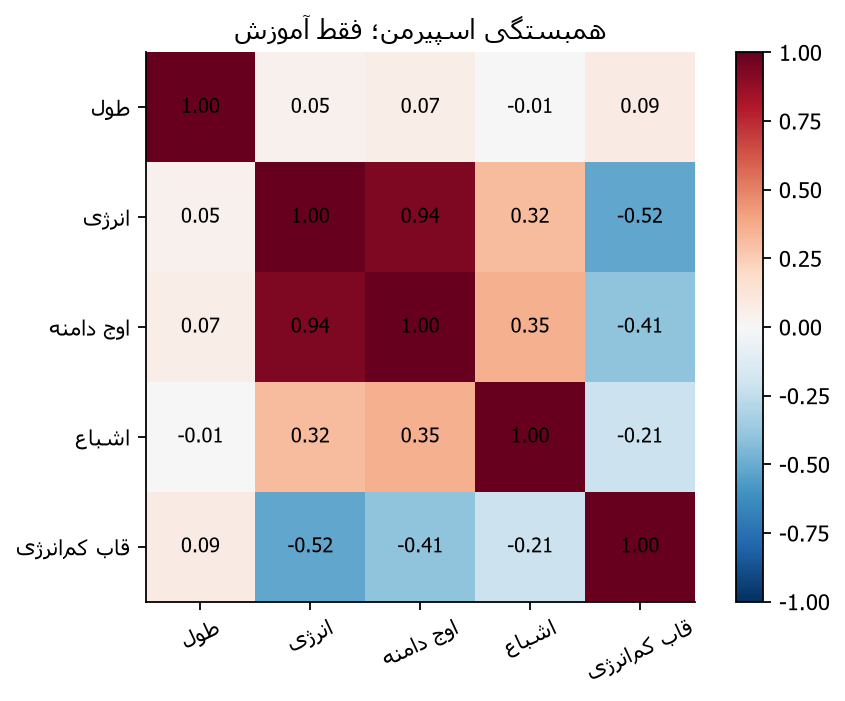

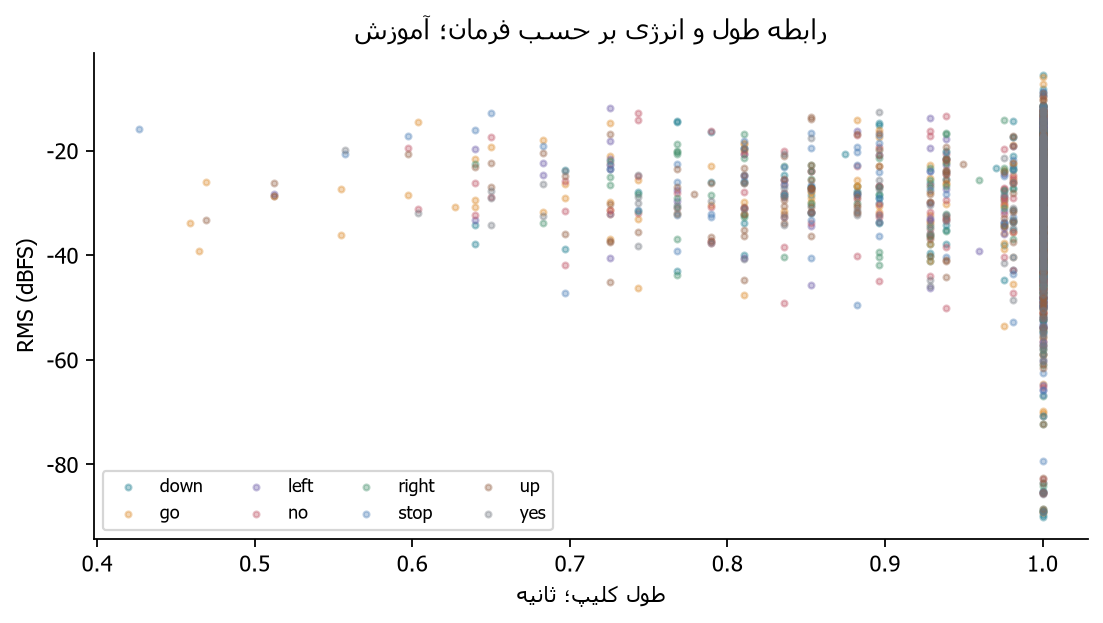

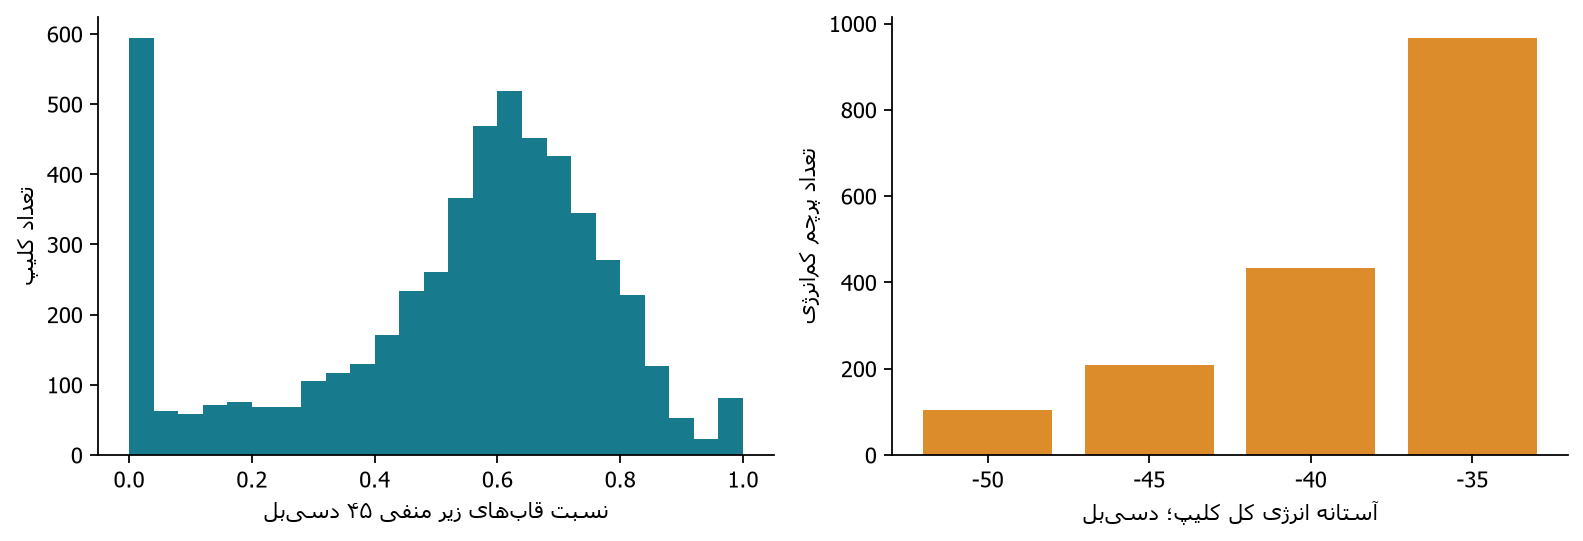

In [8]:
display_table(pd.read_csv(ROOT / "tables/train_spearman.csv", index_col=0))
display_table(pd.read_csv(ROOT / "tables/energy_threshold_sensitivity.csv"))
for filename in ["06_correlations.png", "07_duration_energy.png", "09_low_energy.png"]:
    display(Image(filename=str(ROOT / "figures" / filename)))

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">

## ۸. گویندگان و پوشش فرمان
ممکن است یک گوینده فقط چند فرمان را گفته باشد. جدول کامل تعداد هر فرمان برای هر گوینده ذخیره شده است. مقایسهٔ عملکرد گویندگان در فازهای بعد باید تعداد کم نمونه برای برخی افراد را در نظر بگیرد.

</div>

,speaker_id,down,go,left,no,right,stop,up,yes,total,n_classes
0,004ae714,1,1,0,0,0,0,0,1,3,3
1,00b01445,1,0,1,0,0,0,0,0,2,2
2,00f0204f,1,0,0,0,0,0,0,1,2,2
3,012c8314,0,0,1,1,1,1,0,1,5,5
4,0132a06d,2,1,3,2,3,2,1,2,16,8


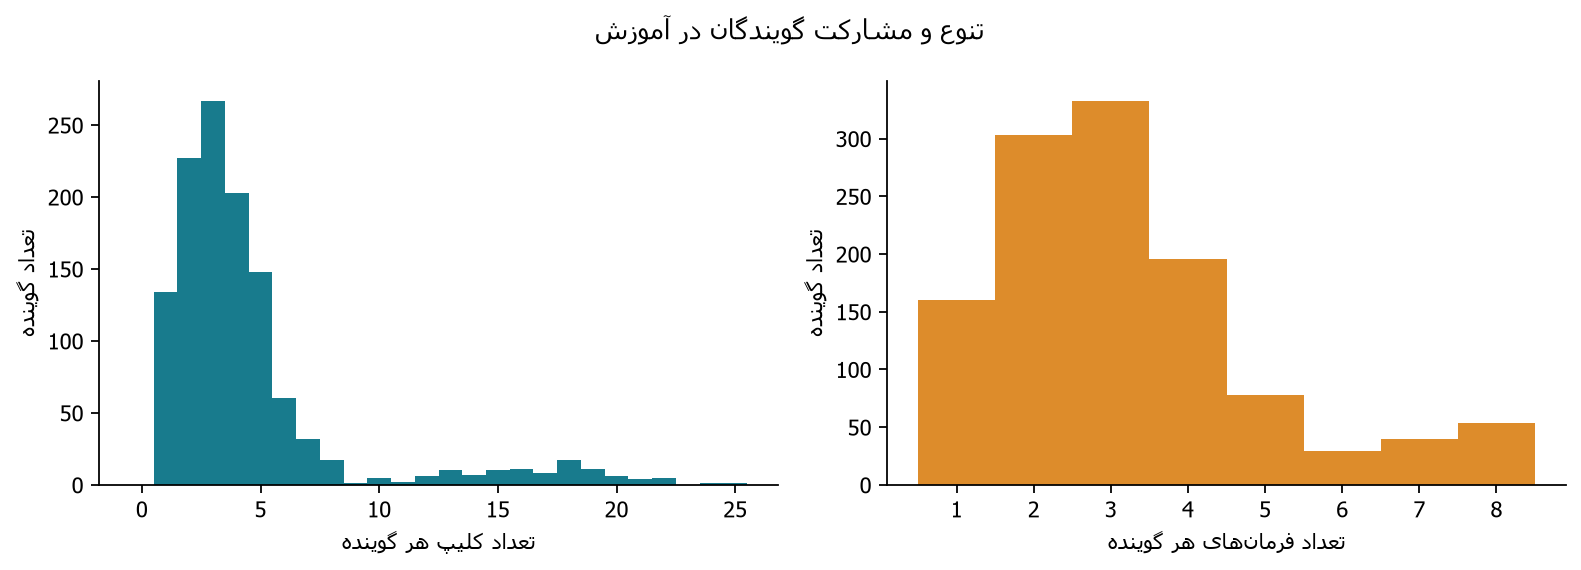

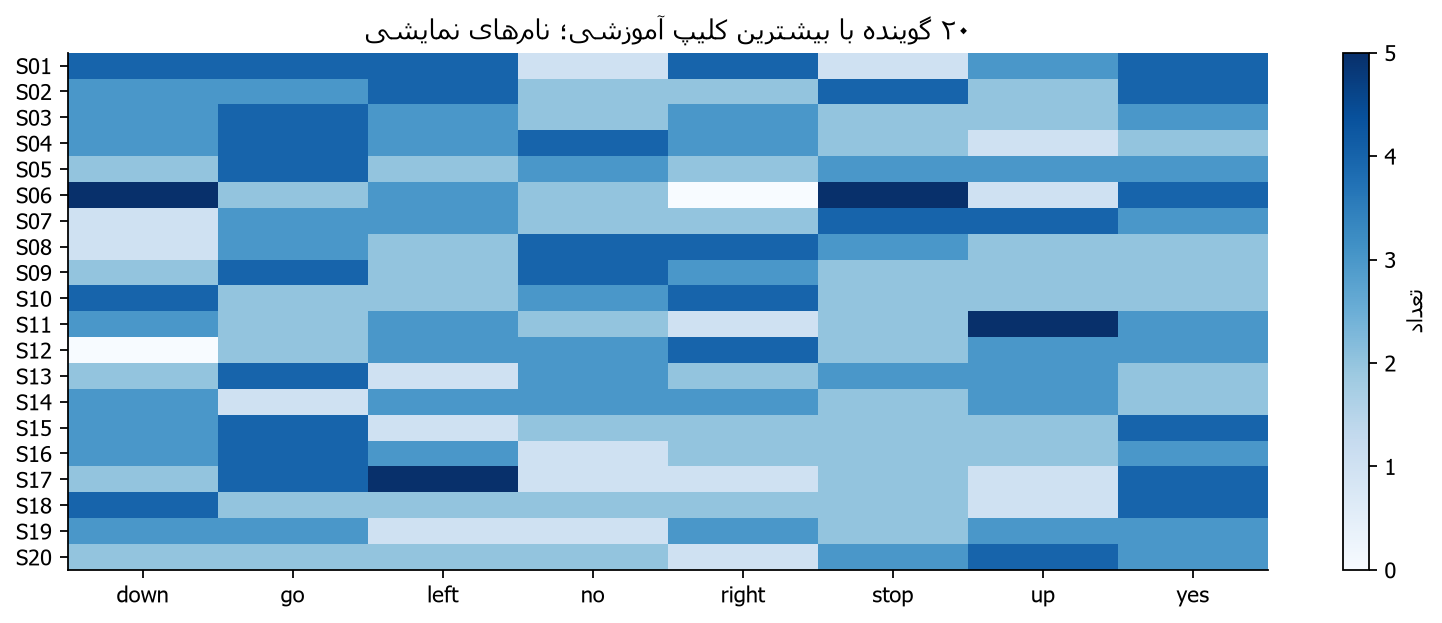

In [9]:
speaker_counts = pd.read_csv(ROOT / "tables/speaker_class_counts.csv")
display_table(speaker_counts.head())
for filename in ["04_speakers.png", "05_speaker_class.png"]:
    display(Image(filename=str(ROOT / "figures" / filename)))

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">

## ۹. موج، طیف و شنیدن نمونه‌ها
برای هر فرمان سه نمونهٔ آموزش با قاعدهٔ هش ثابت انتخاب شده است. محور افقی زمان و محور عمودی طیف بسامد است. شدت رنگ، توان طیفی را نشان می‌دهد و بین شکل‌ها مقیاس یکسان دارد.

در موج‌ها جایگاه زمانی و دامنه تغییر می‌کند. این تفاوت می‌تواند انگیزهٔ بررسی ویژگی‌های مقاوم‌تر باشد؛ هنوز ثابت نمی‌کند یک روش خاص عملکرد بهتر دارد.

</div>

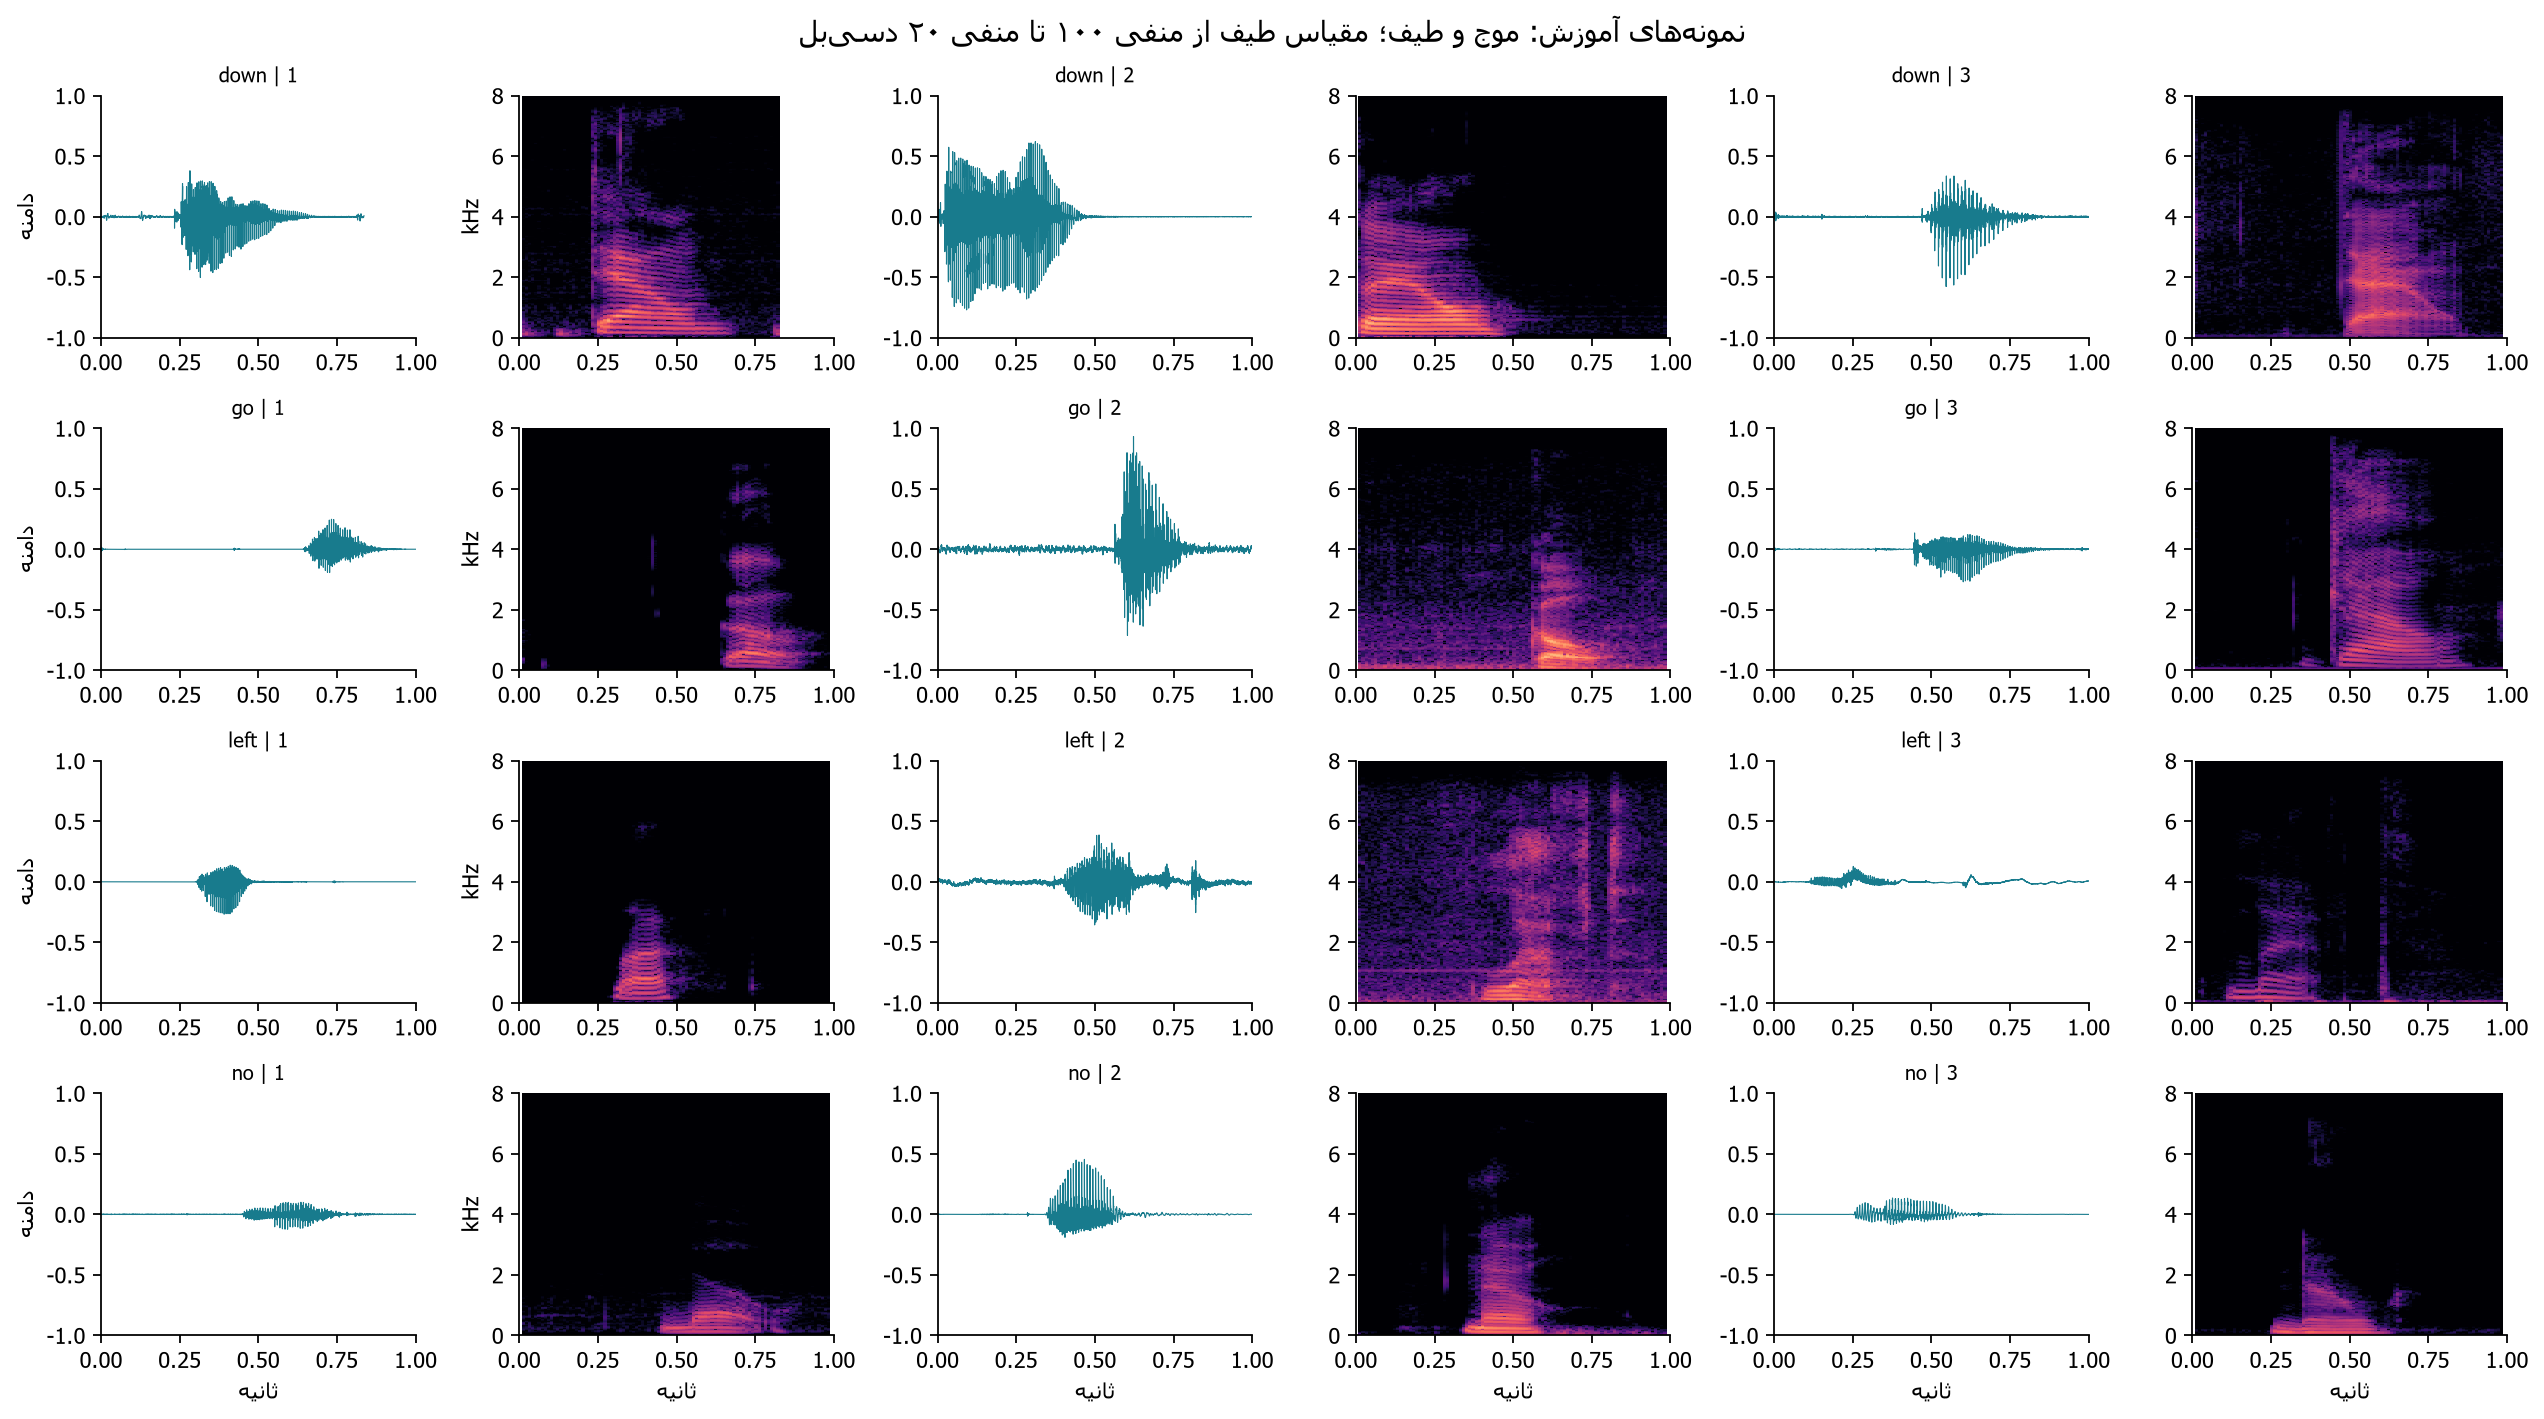

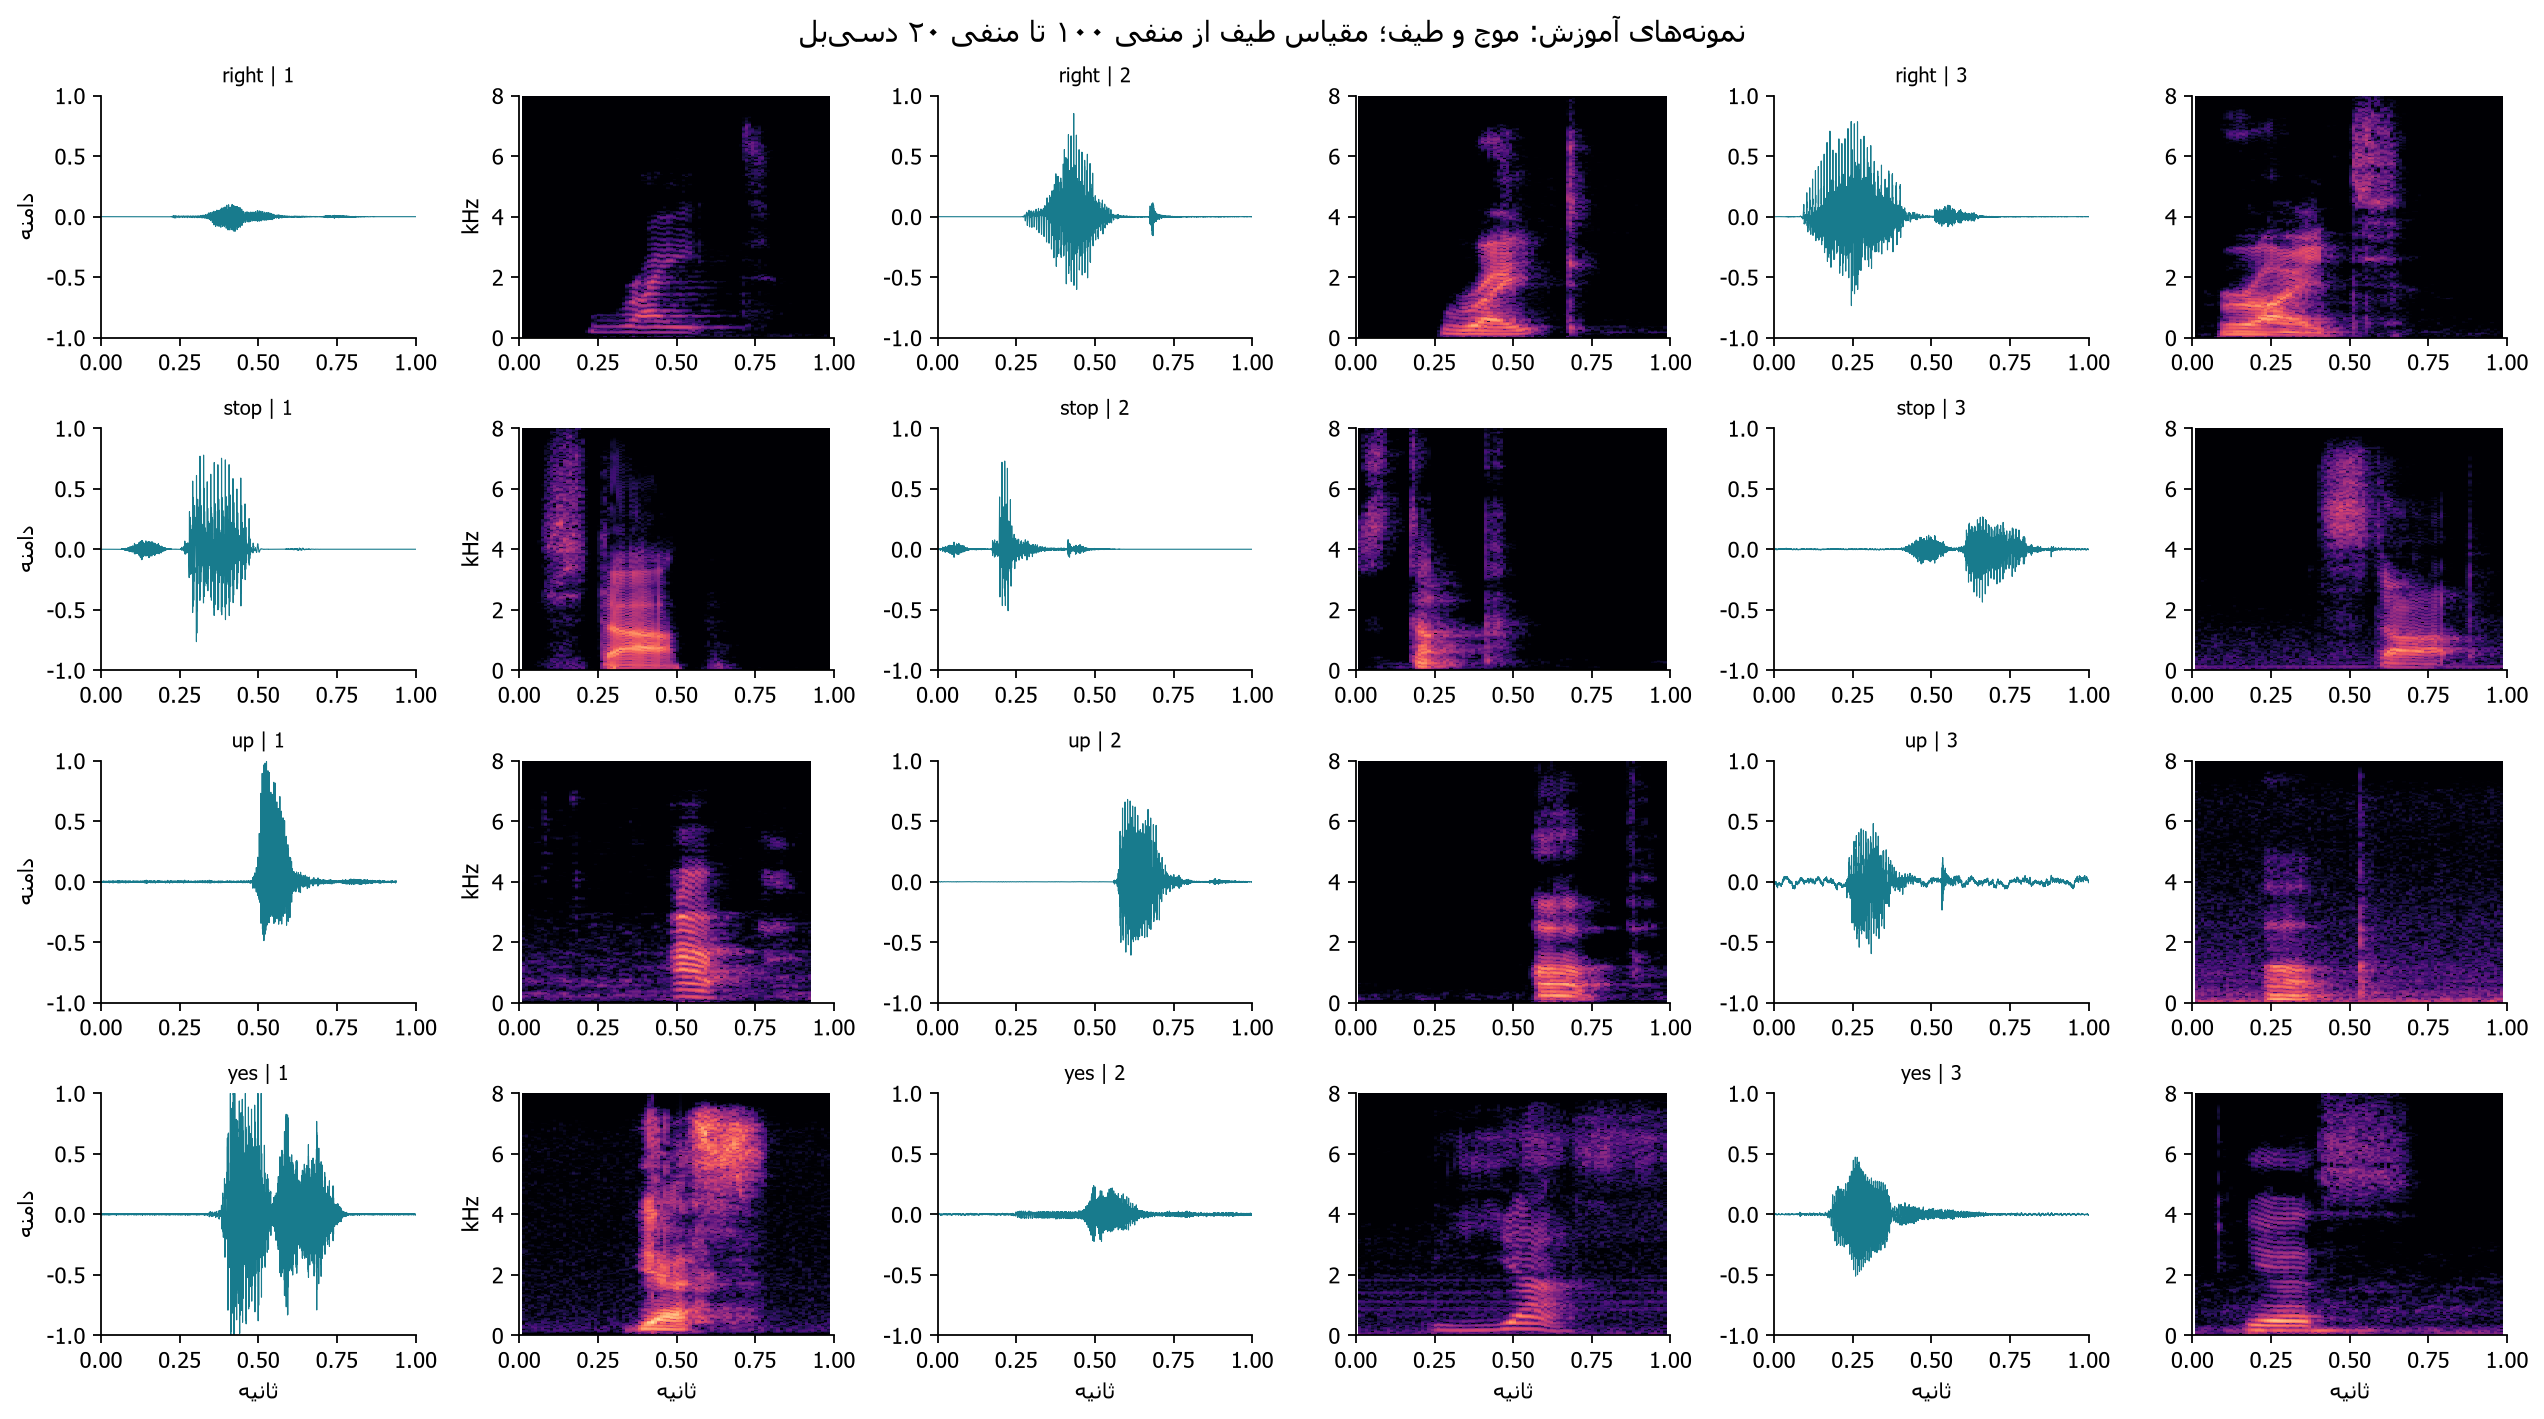

In [10]:
for filename in ["08_examples_1.png", "08_examples_2.png"]:
    display(Image(filename=str(ROOT / "figures" / filename)))

<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">

### بازبینی شنیداری
برای بازبینی شنیداری، اولین نمونهٔ انتخاب‌شدهٔ هر فرمان را در ادامه قرار داده‌ام. صوت با دامنهٔ اصلی نمایش داده می‌شود (`normalize=False`). ابتدا حجم صدای دستگاه را مناسب تنظیم کنید.

پخش‌کننده در خروجی نوت‌بوک به معنی انجام شنود انسانی نیست. برای ثبت نتیجه، فایل `tables/manual_review.csv` را باز کنید و ستون‌های listened، label_correct، audible_noise و notes را پر کنید. صف کامل شامل نمونه‌های نماینده و موارد کم‌انرژی/اشباع نیز هست. اجرای دوبارهٔ ممیزی صف اولیه را بازسازی می‌کند؛

</div>

In [11]:
examples = pd.read_csv(ROOT / "tables/plot_examples.csv")
with zipfile.ZipFile(ROOT / "data/mini_speech_commands.zip") as z:
    for label in cfg["classes"]:
        path = examples.loc[examples.label == label, "path"].iloc[0]
        x, sr, *_ = decode(z.read(path))
        print(label, path)
        display(Audio(data=x, rate=sr, normalize=False))

down mini_speech_commands/down/2296b1af_nohash_0.wav


go mini_speech_commands/go/1942abd7_nohash_1.wav


left mini_speech_commands/left/6846af18_nohash_1.wav


no mini_speech_commands/no/e57d35bc_nohash_1.wav


right mini_speech_commands/right/d31d8dd7_nohash_0.wav


stop mini_speech_commands/stop/f19c1390_nohash_2.wav


up mini_speech_commands/up/caf1803e_nohash_1.wav


yes mini_speech_commands/yes/ab7b5acd_nohash_0.wav


<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">

## ۱۰. خط مبنا و مرز ادعاها
کلاس اکثریت از آموزش انتخاب می‌شود. سهم آن حدود ۱۲٫۷۶٪ است؛ این عدد دقت آزمون نیست. مدل سادهٔ MFCC و مدل طیفی در فاز سوم آموزش خواهند دید.

این Mini کلاس مستقل سکوت و ناشناخته ندارد. بنابراین نرخ فعال‌شدن کاذب در سکوت را نمی‌توان از آن تخمین زد. برای نویز واقعی باید منبع مستقل و مجوز روشن انتخاب شود و ضبط‌های منبع پیش از برش از هم جدا شوند.

</div>

In [12]:
counts = train.label.value_counts().sort_index()
majority = counts.idxmax()
print("کلاس اکثریت آموزش:", majority)
print("سهم این کلاس در آموزش:", round(100 * counts.max() / len(train), 3), "%")
# عمداً هیچ پیش‌بینی یا معیار مدل روی validation/test محاسبه نمی‌شود.

کلاس اکثریت آموزش: right
سهم این کلاس در آموزش: 12.765 %


<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">

## ۱۱. بررسی صحت و تولید جدول گزارش
آزمون‌ها فرمول انرژی و اشباع را روی سیگنال کنترل‌شده، فایل نامعتبر، نبود نشت و آموزش‌بودن نمونه‌های شکل بررسی می‌کنند. فایل‌های مصنوعی فقط برای آزمون فرمول‌اند و هرگز وارد دادهٔ پروژه نمی‌شوند.

</div>

In [13]:
import subprocess
result = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"], cwd=ROOT, capture_output=True, text=True)
print(result.stdout + result.stderr)
assert result.returncode == 0
subprocess.run([sys.executable, "src/build_report_tables.py"], cwd=ROOT, check=True)
print("جدول‌های LaTeX از نتایج واقعی تولید شدند.")

test_amplitude_and_clipping (test_phase1.AuditTests.test_amplitude_and_clipping) ... ok
test_examples_training_only (test_phase1.AuditTests.test_examples_training_only) ... ok
test_invalid_file (test_phase1.AuditTests.test_invalid_file) ... ok
test_saved_integrity (test_phase1.AuditTests.test_saved_integrity) ... ok
test_silent_signal (test_phase1.AuditTests.test_silent_signal) ... ok
test_tone_rms (test_phase1.AuditTests.test_tone_rms) ... ok

----------------------------------------------------------------------
Ran 6 tests in 0.071s

OK

جدول‌های LaTeX از نتایج واقعی تولید شدند.


<div dir="rtl" style="text-align:right; font-family:Tahoma, sans-serif; line-height:1.9">

## ۱۲. نتیجه و بازبینی
داده قابل پردازش است اما تکرار، کم‌انرژی‌بودن و تفاوت مشارکت گویندگان نیازمند توجه‌اند. نسخهٔ تحلیلی ۷۹۷۳ موج یکتا دارد. تقسیم بدون اشتراک گوینده و موج آماده است؛ هنوز مدل یا ادعای عملکرد نداریم.

**منابع:** [آموزش رسمی](https://www.tensorflow.org/tutorials/audio/simple_audio)، [مقالهٔ مجموعه](https://arxiv.org/abs/1804.03209)، [کاتالوگ TFDS برای مقایسهٔ نسخه‌ها](https://www.tensorflow.org/datasets/catalog/speech_commands).

</div>